# DSP Activity 3: Object Counting (Coins) using RGB

Same workflow as **Activity 2**: threshold -> complement -> fill holes -> morphological opening -> label -> `regionprops` -> classify -> draw boxes.

Put `coins.png` in the same folder as this notebook (or change the file name below).

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.measure import label, regionprops
from skimage.morphology import disk, opening, closing

# Activity 3: Object Counting (Coins) using RGB

## 3.1 Load the image and split the RGB channels

Image width: 1231px, height: 1277px, channels: 3


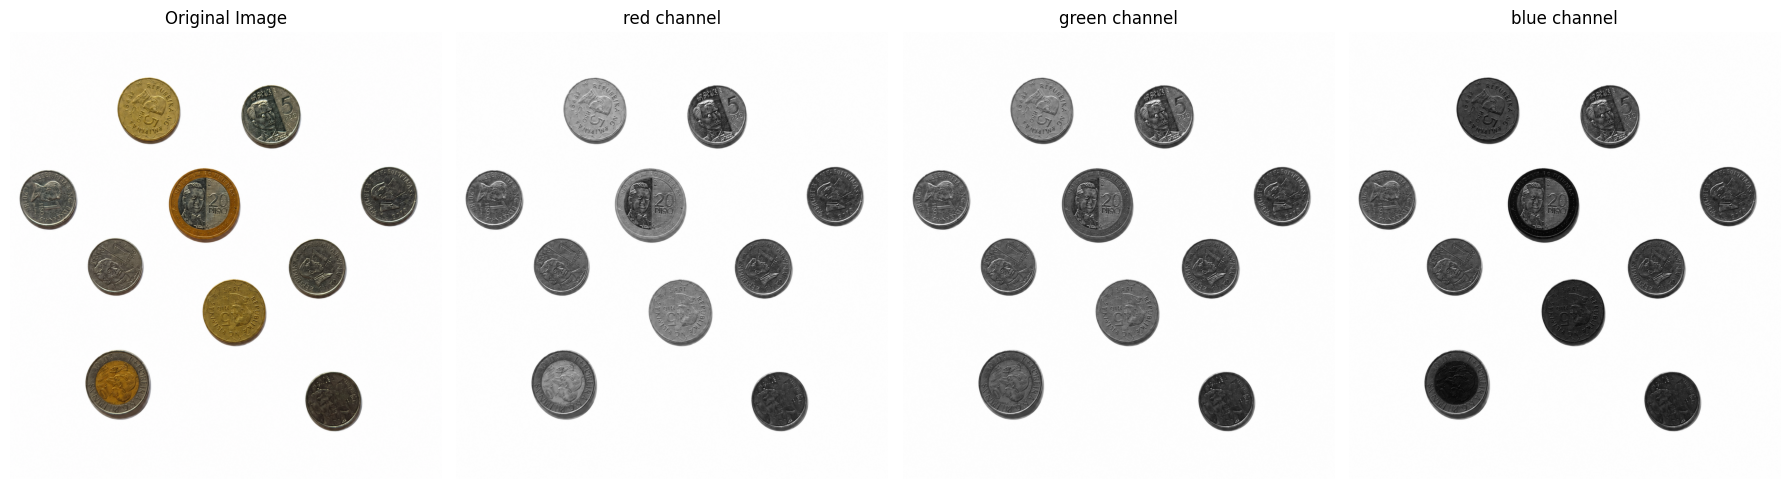

In [2]:
# Load image
image = cv2.imread('coins.png')
if image is None:
    raise FileNotFoundError("Image not found.")

# Convert BGR (OpenCV default) to RGB
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
height, width, channels = image_rgb.shape
print(f"Image width: {width}px, height: {height}px, channels: {channels}")

# Extract channels
rmat = image_rgb[:, :, 0]
gmat = image_rgb[:, :, 1]
bmat = image_rgb[:, :, 2]

fig, axs = plt.subplots(1, 4, figsize=(18, 6))
axs[0].imshow(image_rgb); axs[0].set_title("Original Image")
axs[1].imshow(rmat, cmap='gray'); axs[1].set_title("red channel")
axs[2].imshow(gmat, cmap='gray'); axs[2].set_title("green channel")
axs[3].imshow(bmat, cmap='gray'); axs[3].set_title("blue channel")
for a in axs: a.axis("off")
plt.tight_layout()
plt.show()

## 3.2 Threshold each channel and combine

The background is (near) white, so a pixel is *background* when **R, G and B are all high**. AND-ing the three thresholded channels gives the background mask `It`; its complement `Icomp` is the coins.

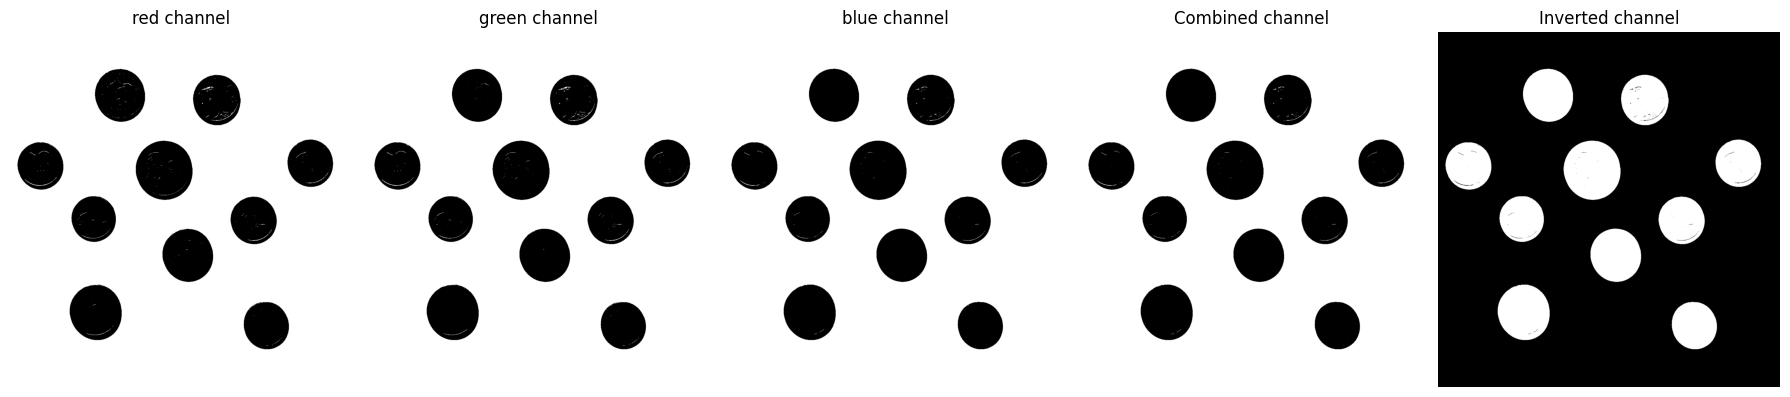

In [3]:
# Threshold levels (background is white -> high levels in all channels)
levelr = 0.85 * 255
levelg = 0.85 * 255
levelb = 0.85 * 255

Ired   = (rmat > levelr).astype(np.uint8)
Igreen = (gmat > levelg).astype(np.uint8)
Iblue  = (bmat > levelb).astype(np.uint8)

# Combine channels (background mask)
It = cv2.bitwise_and(cv2.bitwise_and(Ired, Igreen), Iblue)

# Invert mask -> coins become white
Icomp = cv2.bitwise_not(It * 255)

fig, axs = plt.subplots(1, 5, figsize=(18, 6))
for a, im, t in zip(axs, [Ired, Igreen, Iblue, It, Icomp],
                    ["red channel", "green channel", "blue channel", "Combined channel", "Inverted channel"]):
    a.imshow(im, cmap='gray'); a.set_title(t); a.axis("off")
plt.tight_layout()
plt.show()

## 3.3 Fill holes, clean up, and label the coins

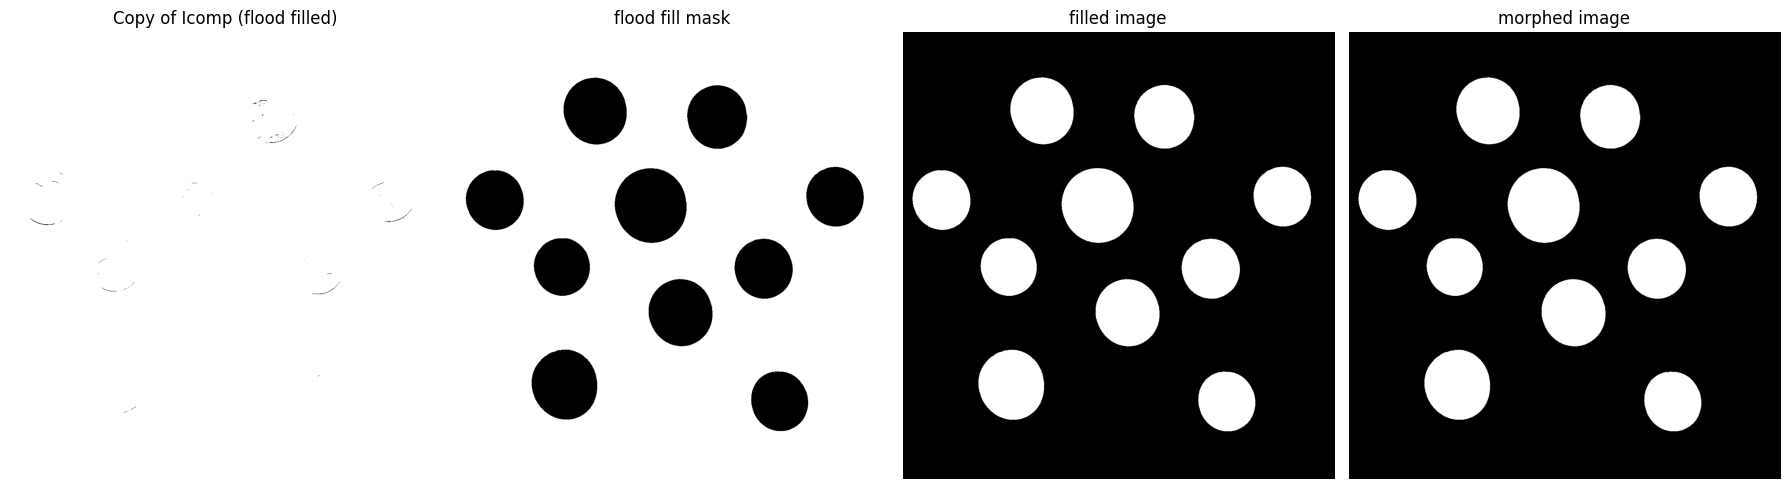

Number of objects found: 10
27032.0
24388.0
21965.0
34372.0
22088.0
20661.0
22245.0
27420.0
29409.0
21864.0


In [4]:
# Fill holes (flood fill from the corner, then invert and OR)
flood_fill = Icomp.copy()
h, w = flood_fill.shape
mask = np.zeros((h+2, w+2), np.uint8)
cv2.floodFill(flood_fill, mask, (0, 0), 255)
filled = cv2.bitwise_or(Icomp, cv2.bitwise_not(flood_fill))

# Morphological opening
opened = opening(filled // 255, disk(10)).astype(np.uint8)

# Label connected components
label_image = label(opened)
regions = regionprops(label_image)

fig, axs = plt.subplots(1, 4, figsize=(18, 6))
for a, im, t in zip(axs, [flood_fill, mask, filled, opened],
                    ["Copy of Icomp (flood filled)", "flood fill mask", "filled image", "morphed image"]):
    a.imshow(im, cmap='gray'); a.set_title(t); a.axis("off")
plt.tight_layout()
plt.show()

# Area of every detected object
print("Number of objects found:", len(regions))
for region in regions:
    print(region.area)

## 3.4 Classify the coins by size (area)

Each Philippine coin has a different diameter, so the **area** of its region separates them. The thresholds below come from the areas printed above:

| Coin | Area range (px) |
|---|---|
| 1 peso (silver, smallest) | < 23,000 |
| 5 peso, new silver (NGC) | 23,000 - 25,500 |
| 5 peso, old gold | 25,500 - 28,500 |
| 10 peso (bimetallic) | 28,500 - 31,500 |
| 20 peso (largest) | >= 31,500 |

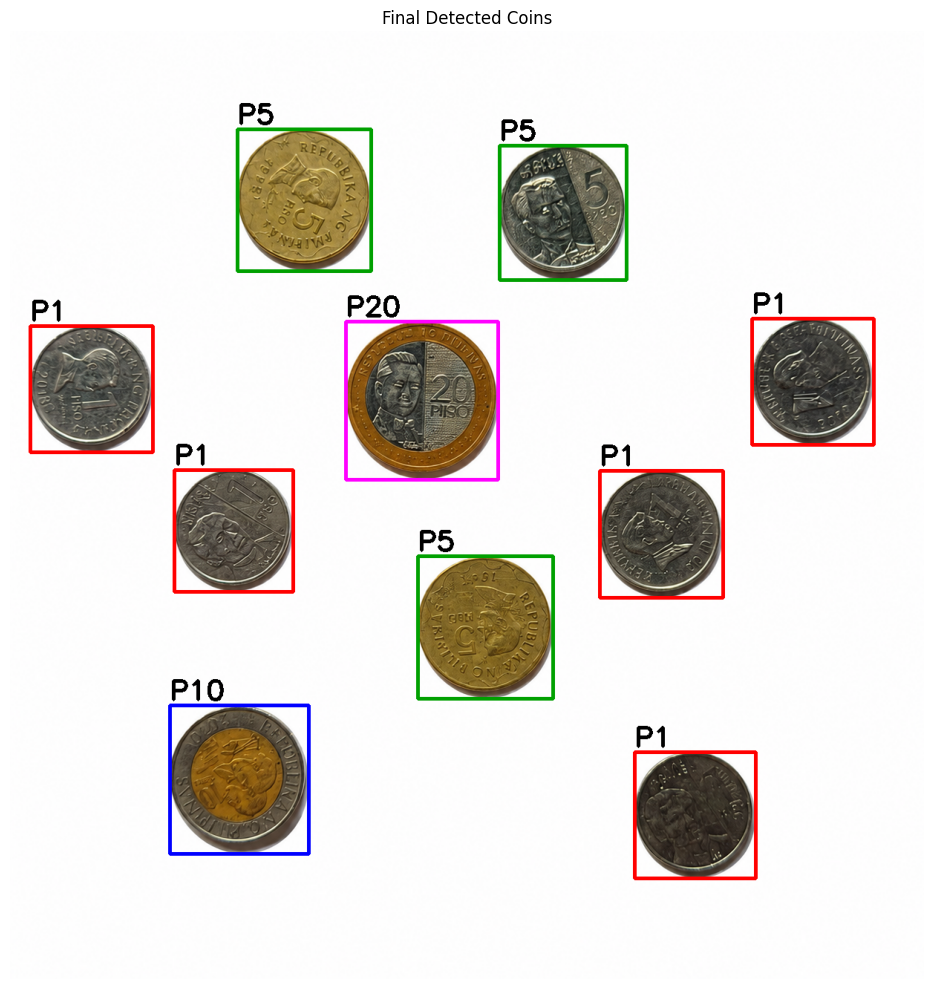

1-peso coins : 5
5-peso coins : 3
10-peso coins: 1
20-peso coins: 1
Total coins  : 10
Total value  : PHP 50


In [5]:
# (upper area limit, label, peso value, box color RGB)
classes = [
    (23000,  'P1',  1,  (255, 0, 0)),
    (25500,  'P5',  5,  (0, 160, 0)),     # new silver 5
    (28500,  'P5',  5,  (0, 160, 0)),     # old gold 5
    (31500,  'P10', 10, (0, 0, 255)),
    (np.inf, 'P20', 20, (255, 0, 255)),
]

def classify(area):
    for limit, name, value, color in classes:
        if area < limit:
            return name, value, color

output_img = image_rgb.copy()
counts = {'P1': 0, 'P5': 0, 'P10': 0, 'P20': 0}
total_value = 0

for region in regions:
    name, value, color = classify(region.area)
    counts[name] += 1
    total_value += value
    minr, minc, maxr, maxc = region.bbox
    cv2.rectangle(output_img, (minc, minr), (maxc, maxr), color, 3)
    cv2.putText(output_img, name, (minc, minr - 8), cv2.FONT_HERSHEY_SIMPLEX, 1.2, (0, 0, 0), 3)

fig, ax = plt.subplots(1, 1, figsize=(10, 10))
ax.imshow(output_img)
ax.set_title("Final Detected Coins")
ax.axis("off")
plt.tight_layout()
plt.show()

print(f"1-peso coins : {counts['P1']}")
print(f"5-peso coins : {counts['P5']}")
print(f"10-peso coins: {counts['P10']}")
print(f"20-peso coins: {counts['P20']}")
print(f"Total coins  : {sum(counts.values())}")
print(f"Total value  : PHP {total_value}")